# Fitting of models
## Installation

>cmdstanpy:  <br>
> pandas: Data manipulation <br>
> numpy: Data calculation <br>
> seaborn: Visualization <br>
> matplotlib.pyplot: Visualization <br>

> fitting: Limited-memory Broyden–Fletcher–Goldfarb–Shanno with Bounds (L-BFGS-B)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
from scipy.optimize import minimize

import os
import sys
from sklearn.metrics import mean_squared_error

!fc-cache -f -v > /dev/null

from matplotlib import pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK JP', 'DejaVu Sans', 'sans-serif']

/bin/bash: line 1: fc-cache: command not found


In [2]:

print(sys.executable)
print(os.getcwd())
print(os.listdir("/workspace"))
# os.listdir()

/usr/local/bin/python
/workspace/scripts/analysis
['.DS_Store', 'requirements.txt', 'references', 'Dockerfile', 'docs', '.devcontainer', 'README.md', 'results', '.gitignore', 'scripts', '.gitattributes', '.git', 'data']


In [3]:
df = pd.read_csv(r"/workspace/data/processed/integrated/data_growth_no_growth_merged.csv", low_memory=False)
df

,Inoculum_size_[CFU/well],Ethanol_[v/v_%],Glycine_[w/v_%],NaCl_[w/v_%],Wavelength_[nm],Bacteria,Elapsed_time_[days],Number_of_growth_well
0,0.91,6.9,NaN,NaN,620,B.cereus,7,57
1,0.91,7.3,NaN,NaN,620,B.cereus,7,16
2,1.01,6.9,NaN,NaN,620,B.cereus,7,50
3,1.01,7.3,NaN,NaN,620,B.cereus,7,10
4,1.05,7.3,NaN,NaN,620,B.cereus,7,1
...,...,...,...,...,...,...,...,...
427,130000.00,NaN,NaN,6.5,596,E.coli,3,96
428,130000.00,NaN,NaN,7.0,596,E.coli,3,79
429,173000.00,NaN,NaN,7.0,596,E.coli,3,80
430,444000.00,NaN,NaN,6.5,596,E.coli,3,96


# Beta-Poisson model

In [4]:
# figure config
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 22

# model definition
def beta_poisson_model(n, alpha, beta):
    return 1 - (1 + n/beta) ** (-alpha)  

# loss function
def loss(params, n, y):
    alpha, beta = params
    pred = beta_poisson_model(n, alpha, beta)
    return np.sum((pred - y) ** 2)

# initial value foralpha, beta
x0 = [0.1, 10.0]
# alpha > 0, beta > 0 
bounds = ((1e-8, None), (1e-8, None),)


def calc_aic(y_obs: np.ndarray, y_pred: np.ndarray, k: int) -> float:
    """
    Calculate AIC assuming Gaussian errors around the model predictions.
    k : number of estimated parameters in the model.
    """
    n = len(y_obs)
    if n == 0:
        return np.nan

    rss = np.sum((y_obs - y_pred) ** 2)
    if rss <= 0:
        return np.nan

    sigma2 = rss / n
    loglik = -0.5 * n * (np.log(2 * np.pi * sigma2) + 1.0)
    aic = 2 * k - 2 * loglik
    return aic

In [6]:

# ======================================
# Result DataFrame and helper functions
# ======================================

RESULTS_DIR = r"/workspace/results/"
os.makedirs(RESULTS_DIR, exist_ok=True)

RESULTS_FILE = os.path.join(RESULTS_DIR, "df_model_fit_results.csv")

RESULT_COLUMNS = [
    "Bacterial_species",
    "Additive_type",
    "Stress_level",
    "Additive_concentration",
    "Elapsed_time_[days]",
    "model_type",
    "RMSE",
    "AIC",
    "parameter_1",
    "parameter_2",
    "parameter_set",    # e.g. "[alpha,beta]", "[p]", "[a0,a1]"
]

# Load existing result file if it exists, otherwise create an empty frame
if os.path.exists(RESULTS_FILE):
    df_results = pd.read_csv(RESULTS_FILE)
else:
    df_results = pd.DataFrame(columns=RESULT_COLUMNS)

display(df_results)
def upsert_result(df_results: pd.DataFrame, row_dict: dict) -> pd.DataFrame:
    """
    Update (if exists) or append (if not) a row identified by
    species + additive + stress + concentration + time + model_type.
    """
    key_cols = [
        "Bacterial_species",
        "Additive_type",
        "Stress_level",
        "Additive_concentration",
        "Elapsed_time_[days]",
        "model_type",
    ]

    if df_results.empty:
        return pd.concat([df_results, pd.DataFrame([row_dict])], ignore_index=True)

    mask = np.ones(len(df_results), dtype=bool)
    for col in key_cols:
        mask &= df_results[col] == row_dict[col]

    if df_results[mask].empty:
        df_results = pd.concat([df_results, pd.DataFrame([row_dict])], ignore_index=True)
    else:
        df_results.loc[mask, row_dict.keys()] = list(row_dict.values())

    return df_results


def add_fit_result(
    df_results: pd.DataFrame,
    *,
    bacterial_species: str,
    additive_type: str,
    stress_level: str,
    additive_concentration: float,
    elapsed_time_days: int,
    model_type: str,
    y_obs: np.ndarray,
    y_pred: np.ndarray,
    params,
    parameter_names,
) -> pd.DataFrame:
    """
    Model-agnostic helper: compute RMSE and AIC and add them to the result DataFrame.

    Parameters
    ----------
    params : sequence of floats
        Estimated parameter values (length 1 or 2).
    parameter_names : sequence of str
        Names of the parameters in the same order as `params`,
        e.g. ["alpha", "beta"], ["p"], ["a0", "a1"].
    """
    params = list(params)
    parameter_names = list(parameter_names)

    # Ensure up to two parameters are stored
    p1 = float(params[0]) if len(params) >= 1 else np.nan
    p2 = float(params[1]) if len(params) >= 2 else np.nan

    # Parameter-name set such as "[alpha,beta]" or "[p]"
    param_set_str = "[" + ",".join(parameter_names) + "]"

    rmse = float(np.sqrt(np.mean((y_pred - y_obs) ** 2)))
    k = len(params)  # number of free parameters
    aic = float(calc_aic(y_obs, y_pred, k=k))

    row = {
        "Bacterial_species": bacterial_species,
        "Additive_type": additive_type,
        "Stress_level": stress_level,
        "Additive_concentration": additive_concentration,
        "Elapsed_time_[days]": elapsed_time_days,
        "model_type": model_type,
        "RMSE": rmse,
        "AIC": aic,
        "parameter_1": p1,
        "parameter_2": p2,
        "parameter_set": param_set_str,
    }
    df_results = upsert_result(df_results, row)
    return df_results


def add_fit_result_from_slice(
    df_results: pd.DataFrame,
    df_slice: pd.DataFrame,
    *,
    stress_level: str,
    additive_col: str,
    model_type: str,
    y_obs: np.ndarray,
    y_pred: np.ndarray,
    params,
    parameter_names,
) -> pd.DataFrame:
    """
    Convenience wrapper: infer metadata (species, elapsed time, additive concentration)
    from a filtered data slice (df_slice) and register RMSE/AIC and parameters.
    """

    # Infer metadata from the first row of the slice
    bacterial_species = df_slice["Bacteria"].iloc[0]
    elapsed_time_days = int(df_slice["Elapsed_time_[days]"].iloc[0])
    additive_concentration = float(df_slice[additive_col].iloc[0])

    df_results = add_fit_result(
        df_results,
        bacterial_species=bacterial_species,
        additive_type=additive_col,
        stress_level=stress_level,
        additive_concentration=additive_concentration,
        elapsed_time_days=elapsed_time_days,
        model_type=model_type,
        y_obs=y_obs,
        y_pred=y_pred,
        params=params,
        parameter_names=parameter_names,
    )
    return df_results



,Bacterial_species,Additive_type,Stress_level,Additive_concentration,Elapsed_time_[days],model_type,RMSE,AIC,parameter_1,parameter_2,parameter_set


## _B. cereus_

### Glycine
- (lower: 1.4% (w/v), higher: 1.6% (w/v))
- (A: Day3, B: Day7)

推定されたalpha,beta(lower, Day3): 1.73139, 184.19102
RMSE (lower, Day3): 0.05923
推定されたalpha,beta(higher, Day3): 15.88838, 269285.80102
RMSE (higher, Day3): 0.05037
推定されたalpha,beta(lower, day7): 1.76001, 19.01156
RMSE (lower, Day7): 0.05044
推定されたalpha,beta(higher, Day7): 11.19117, 109827.91435
RMSE (higher, Day7): 0.02859


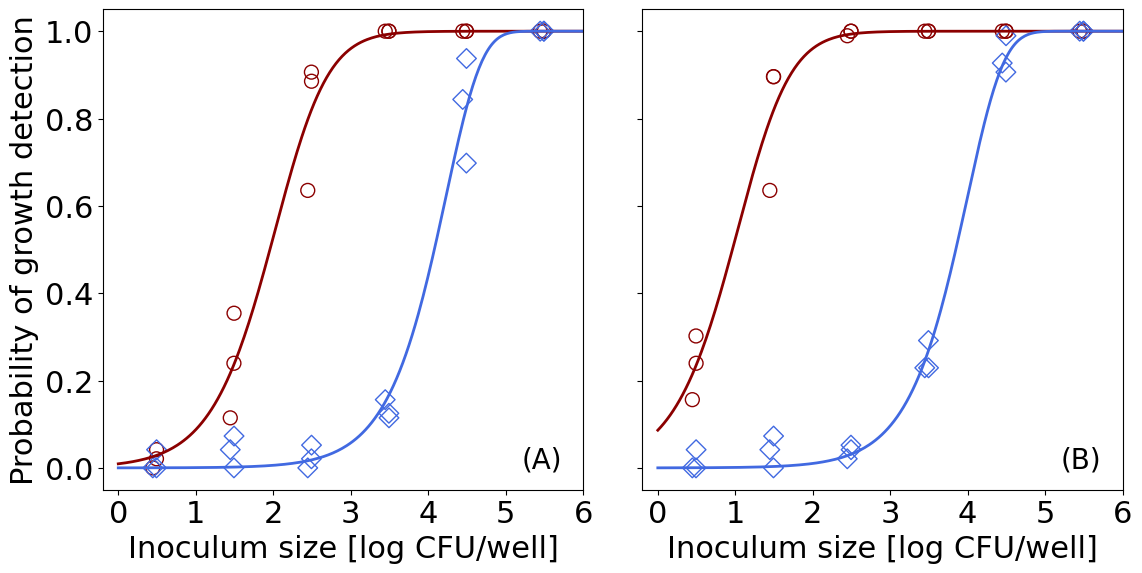

,Bacterial_species,Additive_type,Stress_level,Additive_concentration,Elapsed_time_[days],model_type,RMSE,AIC,parameter_1,parameter_2,parameter_set
0,B.cereus,Glycine_[w/v_%],Low,1.4,3,beta_poisson,0.059229,-46.666569,1.731386,184.191024,"[alpha,beta]"
1,B.cereus,Glycine_[w/v_%],High,1.6,3,beta_poisson,0.050372,-52.498066,15.888383,269285.801017,"[alpha,beta]"
2,B.cereus,Glycine_[w/v_%],Low,1.4,7,beta_poisson,0.050436,-52.451771,1.760015,19.011559,"[alpha,beta]"
3,B.cereus,Glycine_[w/v_%],High,1.6,7,beta_poisson,0.028586,-72.891881,11.191175,109827.914350,"[alpha,beta]"


In [ ]:

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 22

### Beta-Poisson model by least squared method for B. cereus data
df_all = df.copy()
# preprocessing -filtering
## B.cereus, Day3
df_Bc_day3 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 3)
    ].copy()
# lower stress condition
df_Bc_lower_day3 = df_Bc_day3[
    (df_Bc_day3["Glycine_[w/v_%]"] == 1.4) #18
].copy()
# higher stress condition
df_Bc_higher_day3 = df_Bc_day3[
    (df_Bc_day3["Glycine_[w/v_%]"] == 1.6) #18
].copy()

## B.cereus, Day7
df_Bc_day7 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 7)
    ].copy()
# lower stress condition
df_Bc_lower_day7 = df_Bc_day7[
    (df_Bc_day7["Glycine_[w/v_%]"] == 1.4) #18
 ].copy()
# higher stress condition
df_Bc_higher_day7 = df_Bc_day7[
    (df_Bc_day7["Glycine_[w/v_%]"] == 1.6) #18
].copy()


# defining Probability of growth detection "P(n)" & removing if there are missing value
## Day3, lower condition
df_Bc_lower_day3["Growth_probability"] = df_Bc_lower_day3["Number_of_growth_well"] / 96
df_Bc_lower_day3["Inoculum_size"] = df_Bc_lower_day3["Inoculum_size_[CFU/well]"]
df_Bc_lower_day3 = df_Bc_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day3, higher condition
df_Bc_higher_day3["Growth_probability"] = df_Bc_higher_day3["Number_of_growth_well"] / 96
df_Bc_higher_day3["Inoculum_size"] = df_Bc_higher_day3["Inoculum_size_[CFU/well]"]
df_Bc_higher_day3 = df_Bc_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, lower condition
df_Bc_lower_day7["Growth_probability"] = df_Bc_lower_day7["Number_of_growth_well"] / 96
df_Bc_lower_day7["Inoculum_size"] = df_Bc_lower_day7["Inoculum_size_[CFU/well]"]
df_Bc_lower_day7 = df_Bc_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, higher condition
df_Bc_higher_day7["Growth_probability"] = df_Bc_higher_day7["Number_of_growth_well"] / 96
df_Bc_higher_day7["Inoculum_size"] = df_Bc_higher_day7["Inoculum_size_[CFU/well]"]
df_Bc_higher_day7 = df_Bc_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])



# ===== fitting for Day3 =====
## lower Day3
n_lower_3 = df_Bc_lower_day3["Inoculum_size"].values
y_lower_3 = df_Bc_lower_day3["Growth_probability"].values
res_lower_3 = minimize(loss, x0=x0,
                    args=(n_lower_3, y_lower_3),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_lower_3, beta_hat_lower_3 = res_lower_3.x
print(f"推定されたalpha,beta(lower, Day3): {alpha_hat_lower_3:.5f}, {beta_hat_lower_3:.5f}")
# lower additive stress のRMSE
pred_lower_3 = beta_poisson_model(n_lower_3, alpha_hat_lower_3, beta_hat_lower_3)
rmse_lower_3 = np.sqrt(np.mean((pred_lower_3 - y_lower_3) ** 2))
print(f"RMSE (lower, Day3): {rmse_lower_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_lower_day3,
    stress_level="Low",
    additive_col="Glycine_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_lower_3,
    y_pred=pred_lower_3,
    params=[alpha_hat_lower_3, beta_hat_lower_3],
    parameter_names=["alpha", "beta"],
)

n_higher_3 = df_Bc_higher_day3["Inoculum_size"].values
y_higher_3 = df_Bc_higher_day3["Growth_probability"].values
res_higher_3 = minimize(loss, x0=x0,
                    args=(n_higher_3, y_higher_3),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_higher_3, beta_hat_higher_3 = res_higher_3.x
print(f"推定されたalpha,beta(higher, Day3): {alpha_hat_higher_3:.5f}, {beta_hat_higher_3:.5f}")
# higher additive stress のRMSE
pred_higher_3 = beta_poisson_model(n_higher_3, alpha_hat_higher_3, beta_hat_higher_3)
rmse_higher_3 = np.sqrt(np.mean((pred_higher_3 - y_higher_3) ** 2))
print(f"RMSE (higher, Day3): {rmse_higher_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_higher_day3,
    stress_level="High",
    additive_col="Glycine_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_higher_3,
    y_pred=pred_higher_3,
    params=[alpha_hat_higher_3, beta_hat_higher_3],
    parameter_names=["alpha", "beta"],
)

n_plot_lower_3 = np.logspace(0, 6, 300)
y_plot_lower_3 = beta_poisson_model(n_plot_lower_3, alpha_hat_lower_3, beta_hat_lower_3)

n_plot_higher_3 = np.logspace(0, 6, 300)
y_plot_higher_3 = beta_poisson_model(n_plot_higher_3, alpha_hat_higher_3, beta_hat_higher_3)

# ===== fitting for Day7 =====
n_lower_7 = df_Bc_lower_day7["Inoculum_size"].values
y_lower_7 = df_Bc_lower_day7["Growth_probability"].values
res_lower_7 = minimize(loss, x0=x0,
                    args=(n_lower_7, y_lower_7),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_lower_7, beta_hat_lower_7 = res_lower_7.x
print(f"推定されたalpha,beta(lower, day7): {alpha_hat_lower_7:.5f}, {beta_hat_lower_7:.5f}")
# lower additive stress のRMSE
pred_lower_7 = beta_poisson_model(n_lower_7, alpha_hat_lower_7, beta_hat_lower_7)
rmse_lower_7 = np.sqrt(np.mean((pred_lower_7 - y_lower_7) ** 2))
print(f"RMSE (lower, Day7): {rmse_lower_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_lower_day7,
    stress_level="Low",
    additive_col="Glycine_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_lower_7,
    y_pred=pred_lower_7,
    params=[alpha_hat_lower_7, beta_hat_lower_7],
    parameter_names=["alpha", "beta"],
)

n_higher_7 = df_Bc_higher_day7["Inoculum_size"].values
y_higher_7 = df_Bc_higher_day7["Growth_probability"].values
res_higher_7 = minimize(loss, x0=x0,
                    args=(n_higher_7, y_higher_7),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_higher_7, beta_hat_higher_7 = res_higher_7.x
print(f"推定されたalpha,beta(higher, Day7): {alpha_hat_higher_7:.5f}, {beta_hat_higher_7:.5f}")
# higher additive stress のRMSE
pred_higher_7 = beta_poisson_model(n_higher_7, alpha_hat_higher_7, beta_hat_higher_7)
rmse_higher_7 = np.sqrt(np.mean((pred_higher_7 - y_higher_7) ** 2))
print(f"RMSE (higher, Day7): {rmse_higher_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_higher_day7,
    stress_level="High",
    additive_col="Glycine_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_higher_7,
    y_pred=pred_higher_7,
    params=[alpha_hat_higher_7, beta_hat_higher_7],
    parameter_names=["alpha", "beta"],
)

n_plot_lower_7 = np.logspace(0, 6, 300)
y_plot_lower_7 = beta_poisson_model(n_plot_lower_7, alpha_hat_lower_7, beta_hat_lower_7)

n_plot_higher_7 = np.logspace(0, 6, 300)
y_plot_higher_7 = beta_poisson_model(n_plot_higher_7, alpha_hat_higher_7, beta_hat_higher_7)

#### Figure print
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---- (A) Day3 ----
ax = axes[0]
ax.scatter(np.log10(n_lower_3), y_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_3), y_lower_3, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_3), y_plot_lower_3,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_3), y_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_3), y_higher_3, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_3), y_plot_higher_3,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(A)', fontsize=20)
ax.set_box_aspect(1)

# ---- (B) Day7 ----
ax = axes[1]
ax.scatter(np.log10(n_lower_7), y_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_7), y_lower_7, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_7), y_plot_lower_7,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_7), y_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_7), y_higher_7, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_7), y_plot_higher_7,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
# yラベルは左だけでもよければコメントアウトしてOK
# ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(B)', fontsize=20)
ax.set_box_aspect(1)

fig.patch.set_alpha(0)
plt.tight_layout()
plt.show()
display(df_results)

## Saving dataframe as CSV file
# df_results.to_csv(RESULTS_FILE, encoding="utf-8-sig", sep=",", na_rep="", index=False, mode="w")

## Saving Figures
### Glycine
#### Tiff file
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Bcereus_Glycine_14_16_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Bcereus_Glycine_14_16_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)

#### PDF file
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Bcereus_Glycine_14_16_ver2026Jan26th.pdf", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Bcereus_Glycine_14_16_transparent_ver2026Jan26th.pdf", bbox_inches='tight', pad_inches=0.1, transparent=True)


### NaCl
- (lower: 7.0% (w/v), higher: 7.5% (w/v))
- (A: Day3, B: Day7)

推定されたalpha,beta(lower, Day3): 1.74549, 442.32057
RMSE (lower, Day3): 0.11650
推定されたalpha,beta(higher, Day3): 15.05186, 151705.53019
RMSE (higher, Day3): 0.10142
推定されたalpha,beta(lower, day7): 2.52215, 0.59806
RMSE (lower, Day7): 0.04598
推定されたalpha,beta(higher, Day7): 0.84423, 1.65294
RMSE (higher, Day7): 0.05907


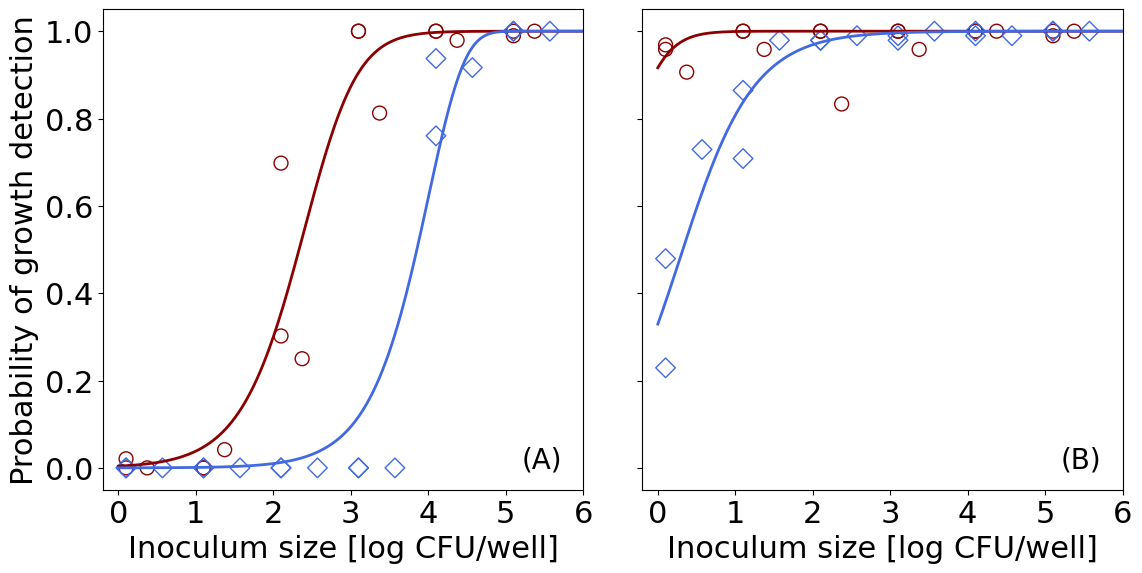

,Bacterial_species,Additive_type,Stress_level,Additive_concentration,Elapsed_time_[days],model_type,RMSE,AIC,parameter_1,parameter_2,parameter_set
0,B.cereus,Glycine_[w/v_%],Low,1.4,3,beta_poisson,0.059229,-46.666569,1.731386,184.191024,"[alpha,beta]"
1,B.cereus,Glycine_[w/v_%],High,1.6,3,beta_poisson,0.050372,-52.498066,15.888383,269285.801017,"[alpha,beta]"
2,B.cereus,Glycine_[w/v_%],Low,1.4,7,beta_poisson,0.050436,-52.451771,1.760015,19.011559,"[alpha,beta]"
3,B.cereus,Glycine_[w/v_%],High,1.6,7,beta_poisson,0.028586,-72.891881,11.191175,109827.914350,"[alpha,beta]"
4,B.cereus,NaCl_[w/v_%],Low,7.0,3,beta_poisson,0.116495,-22.314817,1.745485,442.320573,"[alpha,beta]"
5,B.cereus,NaCl_[w/v_%],High,7.5,3,beta_poisson,0.101425,-27.301949,15.051863,151705.530189,"[alpha,beta]"
6,B.cereus,NaCl_[w/v_%],Low,7.0,7,beta_poisson,0.045979,-55.782610,2.522146,0.598063,"[alpha,beta]"
7,B.cereus,NaCl_[w/v_%],High,7.5,7,beta_poisson,0.059070,-46.763191,0.844231,1.652936,"[alpha,beta]"


In [ ]:

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 22

### Beta-Poisson model by least squared method for B. cereus data
df_all = df.copy()
# preprocessing -filtering
## B.cereus, Day3
df_Bc_day3 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 3)
    ].copy()
# lower stress condition
df_Bc_lower_day3 = df_Bc_day3[
    (df_Bc_day3["NaCl_[w/v_%]"] == 7.0) #18
].copy()
# higher stress condition
df_Bc_higher_day3 = df_Bc_day3[
    (df_Bc_day3["NaCl_[w/v_%]"] == 7.5) #18
].copy()

## B.cereus, Day7
df_Bc_day7 = df_all[
    (df_all["Bacteria"] == "B.cereus") &
    (df_all["Elapsed_time_[days]"] == 7)
    ].copy()
# lower stress condition
df_Bc_lower_day7 = df_Bc_day7[
    (df_Bc_day7["NaCl_[w/v_%]"] == 7.0) #18
].copy()
# higher stress condition
df_Bc_higher_day7 = df_Bc_day7[
    (df_Bc_day7["NaCl_[w/v_%]"] == 7.5) #18
].copy()


# defining Probability of growth detection "P(n)" & removing if there are missing value
## Day3, lower condition
df_Bc_lower_day3["Growth_probability"] = df_Bc_lower_day3["Number_of_growth_well"] / 96
df_Bc_lower_day3["Inoculum_size"] = df_Bc_lower_day3["Inoculum_size_[CFU/well]"]
df_Bc_lower_day3 = df_Bc_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day3, higher condition
df_Bc_higher_day3["Growth_probability"] = df_Bc_higher_day3["Number_of_growth_well"] / 96
df_Bc_higher_day3["Inoculum_size"] = df_Bc_higher_day3["Inoculum_size_[CFU/well]"]
df_Bc_higher_day3 = df_Bc_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, lower condition
df_Bc_lower_day7["Growth_probability"] = df_Bc_lower_day7["Number_of_growth_well"] / 96
df_Bc_lower_day7["Inoculum_size"] = df_Bc_lower_day7["Inoculum_size_[CFU/well]"]
df_Bc_lower_day7 = df_Bc_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, higher condition
df_Bc_higher_day7["Growth_probability"] = df_Bc_higher_day7["Number_of_growth_well"] / 96
df_Bc_higher_day7["Inoculum_size"] = df_Bc_higher_day7["Inoculum_size_[CFU/well]"]
df_Bc_higher_day7 = df_Bc_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])



# ===== fitting for Day3 =====
## lower Day3
n_lower_3 = df_Bc_lower_day3["Inoculum_size"].values
y_lower_3 = df_Bc_lower_day3["Growth_probability"].values
res_lower_3 = minimize(loss, x0=x0,
                    args=(n_lower_3, y_lower_3),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_lower_3, beta_hat_lower_3 = res_lower_3.x
print(f"推定されたalpha,beta(lower, Day3): {alpha_hat_lower_3:.5f}, {beta_hat_lower_3:.5f}")
# lower additive stress のRMSE
pred_lower_3 = beta_poisson_model(n_lower_3, alpha_hat_lower_3, beta_hat_lower_3)
rmse_lower_3 = np.sqrt(np.mean((pred_lower_3 - y_lower_3) ** 2))
print(f"RMSE (lower, Day3): {rmse_lower_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_lower_day3,
    stress_level="Low",
    additive_col="NaCl_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_lower_3,
    y_pred=pred_lower_3,
    params=[alpha_hat_lower_3, beta_hat_lower_3],
    parameter_names=["alpha", "beta"],
)

n_higher_3 = df_Bc_higher_day3["Inoculum_size"].values
y_higher_3 = df_Bc_higher_day3["Growth_probability"].values
res_higher_3 = minimize(loss, x0=x0,
                    args=(n_higher_3, y_higher_3),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_higher_3, beta_hat_higher_3 = res_higher_3.x
print(f"推定されたalpha,beta(higher, Day3): {alpha_hat_higher_3:.5f}, {beta_hat_higher_3:.5f}")
# higher additive stress のRMSE
pred_higher_3 = beta_poisson_model(n_higher_3, alpha_hat_higher_3, beta_hat_higher_3)
rmse_higher_3 = np.sqrt(np.mean((pred_higher_3 - y_higher_3) ** 2))
print(f"RMSE (higher, Day3): {rmse_higher_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_higher_day3,
    stress_level="High",
    additive_col="NaCl_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_higher_3,
    y_pred=pred_higher_3,
    params=[alpha_hat_higher_3, beta_hat_higher_3],
    parameter_names=["alpha", "beta"],
)

n_plot_lower_3 = np.logspace(0, 6, 300)
y_plot_lower_3 = beta_poisson_model(n_plot_lower_3, alpha_hat_lower_3, beta_hat_lower_3)

n_plot_higher_3 = np.logspace(0, 6, 300)
y_plot_higher_3 = beta_poisson_model(n_plot_higher_3, alpha_hat_higher_3, beta_hat_higher_3)

# ===== fitting for Day7 =====
n_lower_7 = df_Bc_lower_day7["Inoculum_size"].values
y_lower_7 = df_Bc_lower_day7["Growth_probability"].values
res_lower_7 = minimize(loss, x0=x0,
                    args=(n_lower_7, y_lower_7),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_lower_7, beta_hat_lower_7 = res_lower_7.x
print(f"推定されたalpha,beta(lower, day7): {alpha_hat_lower_7:.5f}, {beta_hat_lower_7:.5f}")
# lower additive stress のRMSE
pred_lower_7 = beta_poisson_model(n_lower_7, alpha_hat_lower_7, beta_hat_lower_7)
rmse_lower_7 = np.sqrt(np.mean((pred_lower_7 - y_lower_7) ** 2))
print(f"RMSE (lower, Day7): {rmse_lower_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_lower_day7,
    stress_level="Low",
    additive_col="NaCl_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_lower_7,
    y_pred=pred_lower_7,
    params=[alpha_hat_lower_7, beta_hat_lower_7],
    parameter_names=["alpha", "beta"],
)

n_higher_7 = df_Bc_higher_day7["Inoculum_size"].values
y_higher_7 = df_Bc_higher_day7["Growth_probability"].values
res_higher_7 = minimize(loss, x0=x0,
                    args=(n_higher_7, y_higher_7),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_higher_7, beta_hat_higher_7 = res_higher_7.x
print(f"推定されたalpha,beta(higher, Day7): {alpha_hat_higher_7:.5f}, {beta_hat_higher_7:.5f}")
# higher additive stress のRMSE
pred_higher_7 = beta_poisson_model(n_higher_7, alpha_hat_higher_7, beta_hat_higher_7)
rmse_higher_7 = np.sqrt(np.mean((pred_higher_7 - y_higher_7) ** 2))
print(f"RMSE (higher, Day7): {rmse_higher_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Bc_higher_day7,
    stress_level="High",
    additive_col="NaCl_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_higher_7,
    y_pred=pred_higher_7,
    params=[alpha_hat_higher_7, beta_hat_higher_7],
    parameter_names=["alpha", "beta"],
)

n_plot_lower_7 = np.logspace(0, 6, 300)
y_plot_lower_7 = beta_poisson_model(n_plot_lower_7, alpha_hat_lower_7, beta_hat_lower_7)

n_plot_higher_7 = np.logspace(0, 6, 300)
y_plot_higher_7 = beta_poisson_model(n_plot_higher_7, alpha_hat_higher_7, beta_hat_higher_7)

#### Figure print
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---- (A) Day3 ----
ax = axes[0]
ax.scatter(np.log10(n_lower_3), y_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_3), y_lower_3, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_3), y_plot_lower_3,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_3), y_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_3), y_higher_3, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_3), y_plot_higher_3,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(A)', fontsize=20)
ax.set_box_aspect(1)

# ---- (B) Day7 ----
ax = axes[1]
ax.scatter(np.log10(n_lower_7), y_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_7), y_lower_7, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_7), y_plot_lower_7,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_7), y_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_7), y_higher_7, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_7), y_plot_higher_7,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
# yラベルは左だけでもよければコメントアウトしてOK
# ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(B)', fontsize=20)
ax.set_box_aspect(1)

fig.patch.set_alpha(0)
plt.tight_layout()
plt.show()
display(df_results)

## Saving dataframe as CSV file
# df_results.to_csv(RESULTS_FILE, encoding="utf-8-sig", sep=",", na_rep="", index=False, mode="w")

## Saving Figures
### NaCl
#### TIFF
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Bcereus_NaCl_70_75_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Bcereus_NaCl_70_75_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)

#### PDF
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Bcereus_NaCl_70_75_ver2026Jan26th.pdf", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Bcereus_NaCl_70_75_transparent_ver2026Jan26th.pdf", bbox_inches='tight', pad_inches=0.1, transparent=True)

# _E. coli_

### Glycine
- (lower: 1.7% (w/v), higher: 1.8% (w/v))
- (A: Day3, B: Day7)

推定されたalpha,beta(lower, Day3): 4.63620, 145093.80281
RMSE (lower, Day3): 0.04263
推定されたalpha,beta(higher, Day3): 896.40809, 103147011.33284
RMSE (higher, Day3): 0.02377
推定されたalpha,beta(lower, day7): 4.60521, 124816.12058
RMSE (lower, Day7): 0.04163
推定されたalpha,beta(higher, Day7): 10.39189, 996507.11851
RMSE (higher, Day7): 0.01976


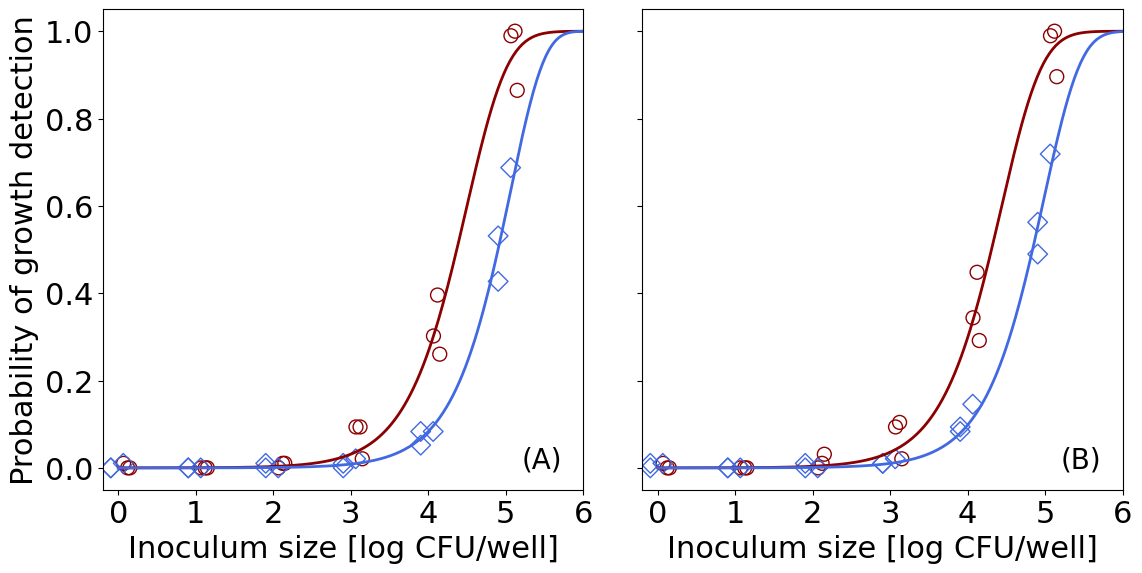

,Bacterial_species,Additive_type,Stress_level,Additive_concentration,Elapsed_time_[days],model_type,RMSE,AIC,parameter_1,parameter_2,parameter_set
0,B.cereus,Glycine_[w/v_%],Low,1.4,3,beta_poisson,0.059229,-46.666569,1.731386,1.841910e+02,"[alpha,beta]"
1,B.cereus,Glycine_[w/v_%],High,1.6,3,beta_poisson,0.050372,-52.498066,15.888383,2.692858e+05,"[alpha,beta]"
2,B.cereus,Glycine_[w/v_%],Low,1.4,7,beta_poisson,0.050436,-52.451771,1.760015,1.901156e+01,"[alpha,beta]"
3,B.cereus,Glycine_[w/v_%],High,1.6,7,beta_poisson,0.028586,-72.891881,11.191175,1.098279e+05,"[alpha,beta]"
4,B.cereus,NaCl_[w/v_%],Low,7.0,3,beta_poisson,0.116495,-22.314817,1.745485,4.423206e+02,"[alpha,beta]"
5,B.cereus,NaCl_[w/v_%],High,7.5,3,beta_poisson,0.101425,-27.301949,15.051863,1.517055e+05,"[alpha,beta]"
6,B.cereus,NaCl_[w/v_%],Low,7.0,7,beta_poisson,0.045979,-55.782610,2.522146,5.980634e-01,"[alpha,beta]"
7,B.cereus,NaCl_[w/v_%],High,7.5,7,beta_poisson,0.059070,-46.763191,0.844231,1.652936e+00,"[alpha,beta]"
8,E.coli,Glycine_[w/v_%],Low,1.7,3,beta_poisson,0.042627,-58.507600,4.636197,1.450938e+05,"[alpha,beta]"
9,E.coli,Glycine_[w/v_%],High,1.8,3,beta_poisson,0.023767,-79.539096,896.408088,1.031470e+08,"[alpha,beta]"


In [ ]:
### Beta-Poisson model by least squared method for E. coli data

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 22

df_all = df.copy()
# preprocessing -filtering
## E.coli, Day3
df_Ec_day3 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 3)
    ].copy()
# lower stress condition
df_Ec_lower_day3 = df_Ec_day3[
    (df_Ec_day3["Glycine_[w/v_%]"] == 1.7) #18
].copy()
# higher stress condition
df_Ec_higher_day3 = df_Ec_day3[
    (df_Ec_day3["Glycine_[w/v_%]"] == 1.8) #18
].copy()

## E.coli, Day7
df_Ec_day7 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 7)
    ].copy()
# lower stress condition
df_Ec_lower_day7 = df_Ec_day7[
    (df_Ec_day7["Glycine_[w/v_%]"] == 1.7) #18
].copy()
# higher stress condition
df_Ec_higher_day7 = df_Ec_day7[
    (df_Ec_day7["Glycine_[w/v_%]"] == 1.8) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
## Day3, lower condition
df_Ec_lower_day3["Growth_probability"] = df_Ec_lower_day3["Number_of_growth_well"] / 96
df_Ec_lower_day3["Inoculum_size"] = df_Ec_lower_day3["Inoculum_size_[CFU/well]"]
df_Ec_lower_day3 = df_Ec_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day3, higher condition
df_Ec_higher_day3["Growth_probability"] = df_Ec_higher_day3["Number_of_growth_well"] / 96
df_Ec_higher_day3["Inoculum_size"] = df_Ec_higher_day3["Inoculum_size_[CFU/well]"]
df_Ec_higher_day3 = df_Ec_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, lower condition
df_Ec_lower_day7["Growth_probability"] = df_Ec_lower_day7["Number_of_growth_well"] / 96
df_Ec_lower_day7["Inoculum_size"] = df_Ec_lower_day7["Inoculum_size_[CFU/well]"]
df_Ec_lower_day7 = df_Ec_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, higher condition
df_Ec_higher_day7["Growth_probability"] = df_Ec_higher_day7["Number_of_growth_well"] / 96
df_Ec_higher_day7["Inoculum_size"] = df_Ec_higher_day7["Inoculum_size_[CFU/well]"]
df_Ec_higher_day7 = df_Ec_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])



# ===== fitting for Day3 =====
## lower Day3
n_lower_3 = df_Ec_lower_day3["Inoculum_size"].values
y_lower_3 = df_Ec_lower_day3["Growth_probability"].values
res_lower_3 = minimize(loss, x0=x0,
                    args=(n_lower_3, y_lower_3),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_lower_3, beta_hat_lower_3 = res_lower_3.x
print(f"推定されたalpha,beta(lower, Day3): {alpha_hat_lower_3:.5f}, {beta_hat_lower_3:.5f}")
# lower additive stress のRMSE
pred_lower_3 = beta_poisson_model(n_lower_3, alpha_hat_lower_3, beta_hat_lower_3)
rmse_lower_3 = np.sqrt(np.mean((pred_lower_3 - y_lower_3) ** 2))
print(f"RMSE (lower, Day3): {rmse_lower_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_lower_day3,
    stress_level="Low",
    additive_col="Glycine_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_lower_3,
    y_pred=pred_lower_3,
    params=[alpha_hat_lower_3, beta_hat_lower_3],
    parameter_names=["alpha", "beta"],
)

n_higher_3 = df_Ec_higher_day3["Inoculum_size"].values
y_higher_3 = df_Ec_higher_day3["Growth_probability"].values
res_higher_3 = minimize(loss, x0=x0,
                    args=(n_higher_3, y_higher_3),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_higher_3, beta_hat_higher_3 = res_higher_3.x
print(f"推定されたalpha,beta(higher, Day3): {alpha_hat_higher_3:.5f}, {beta_hat_higher_3:.5f}")
# higher additive stress のRMSE
pred_higher_3 = beta_poisson_model(n_higher_3, alpha_hat_higher_3, beta_hat_higher_3)
rmse_higher_3 = np.sqrt(np.mean((pred_higher_3 - y_higher_3) ** 2))
print(f"RMSE (higher, Day3): {rmse_higher_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_higher_day3,
    stress_level="High",
    additive_col="Glycine_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_higher_3,
    y_pred=pred_higher_3,
    params=[alpha_hat_higher_3, beta_hat_higher_3],
    parameter_names=["alpha", "beta"],
)

n_plot_lower_3 = np.logspace(0, 6, 300)
y_plot_lower_3 = beta_poisson_model(n_plot_lower_3, alpha_hat_lower_3, beta_hat_lower_3)

n_plot_higher_3 = np.logspace(0, 6, 300)
y_plot_higher_3 = beta_poisson_model(n_plot_higher_3, alpha_hat_higher_3, beta_hat_higher_3)

# ===== fitting for Day7 =====
n_lower_7 = df_Ec_lower_day7["Inoculum_size"].values
y_lower_7 = df_Ec_lower_day7["Growth_probability"].values
res_lower_7 = minimize(loss, x0=x0,
                    args=(n_lower_7, y_lower_7),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_lower_7, beta_hat_lower_7 = res_lower_7.x
print(f"推定されたalpha,beta(lower, day7): {alpha_hat_lower_7:.5f}, {beta_hat_lower_7:.5f}")
# lower additive stress のRMSE
pred_lower_7 = beta_poisson_model(n_lower_7, alpha_hat_lower_7, beta_hat_lower_7)
rmse_lower_7 = np.sqrt(np.mean((pred_lower_7 - y_lower_7) ** 2))
print(f"RMSE (lower, Day7): {rmse_lower_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_lower_day7,
    stress_level="Low",
    additive_col="Glycine_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_lower_7,
    y_pred=pred_lower_7,
    params=[alpha_hat_lower_7, beta_hat_lower_7],
    parameter_names=["alpha", "beta"],
)

n_higher_7 = df_Ec_higher_day7["Inoculum_size"].values
y_higher_7 = df_Ec_higher_day7["Growth_probability"].values
res_higher_7 = minimize(loss, x0=x0,
                    args=(n_higher_7, y_higher_7),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_higher_7, beta_hat_higher_7 = res_higher_7.x
print(f"推定されたalpha,beta(higher, Day7): {alpha_hat_higher_7:.5f}, {beta_hat_higher_7:.5f}")
# higher additive stress のRMSE
pred_higher_7 = beta_poisson_model(n_higher_7, alpha_hat_higher_7, beta_hat_higher_7)
rmse_higher_7 = np.sqrt(np.mean((pred_higher_7 - y_higher_7) ** 2))
print(f"RMSE (higher, Day7): {rmse_higher_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_higher_day7,
    stress_level="High",
    additive_col="Glycine_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_higher_7,
    y_pred=pred_higher_7,
    params=[alpha_hat_higher_7, beta_hat_higher_7],
    parameter_names=["alpha", "beta"],
)

n_plot_lower_7 = np.logspace(0, 6, 300)
y_plot_lower_7 = beta_poisson_model(n_plot_lower_7, alpha_hat_lower_7, beta_hat_lower_7)

n_plot_higher_7 = np.logspace(0, 6, 300)
y_plot_higher_7 = beta_poisson_model(n_plot_higher_7, alpha_hat_higher_7, beta_hat_higher_7)

#### Figure print
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---- (A) Day3 ----
ax = axes[0]
ax.scatter(np.log10(n_lower_3), y_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_3), y_lower_3, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_3), y_plot_lower_3,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_3), y_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_3), y_higher_3, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_3), y_plot_higher_3,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(A)', fontsize=20)
ax.set_box_aspect(1)

# ---- (B) Day7 ----
ax = axes[1]
ax.scatter(np.log10(n_lower_7), y_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_7), y_lower_7, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_7), y_plot_lower_7,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_7), y_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_7), y_higher_7, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_7), y_plot_higher_7,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
# yラベルは左だけでもよければコメントアウトしてOK
# ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(B)', fontsize=20)
ax.set_box_aspect(1)

fig.patch.set_alpha(0)
plt.tight_layout()
plt.show()
display(df_results)

## Saving dataframe as CSV file
# df_results.to_csv(RESULTS_FILE, encoding="utf-8-sig", sep=",", na_rep="", index=False, mode="w")

## Saving Figures
### Glycine
#### TIFF
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Ecoli_Glycine_17_18_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Ecoli_Glycine_17_18_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)

#### PDF
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Ecoli_Glycine_17_18_ver2026Jan26th.pdf", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Ecoli_Glycine_17_18_transparent_ver2026Jan26th.pdf", bbox_inches='tight', pad_inches=0.1, transparent=True)

### NaCl
- (lower: 6.5% (w/v), higher: 7.0% (w/v))
- (A: Day3, B: Day7)

推定されたalpha,beta(lower, Day3): 100.18638, 91865.04790
RMSE (lower, Day3): 0.10198
推定されたalpha,beta(higher, Day3): 76.75173, 6402289.22710
RMSE (higher, Day3): 0.06257
推定されたalpha,beta(lower, day7): 51.56473, 360.11358
RMSE (lower, Day7): 0.08433
推定されたalpha,beta(higher, Day7): 1.62194, 32.24011
RMSE (higher, Day7): 0.06202


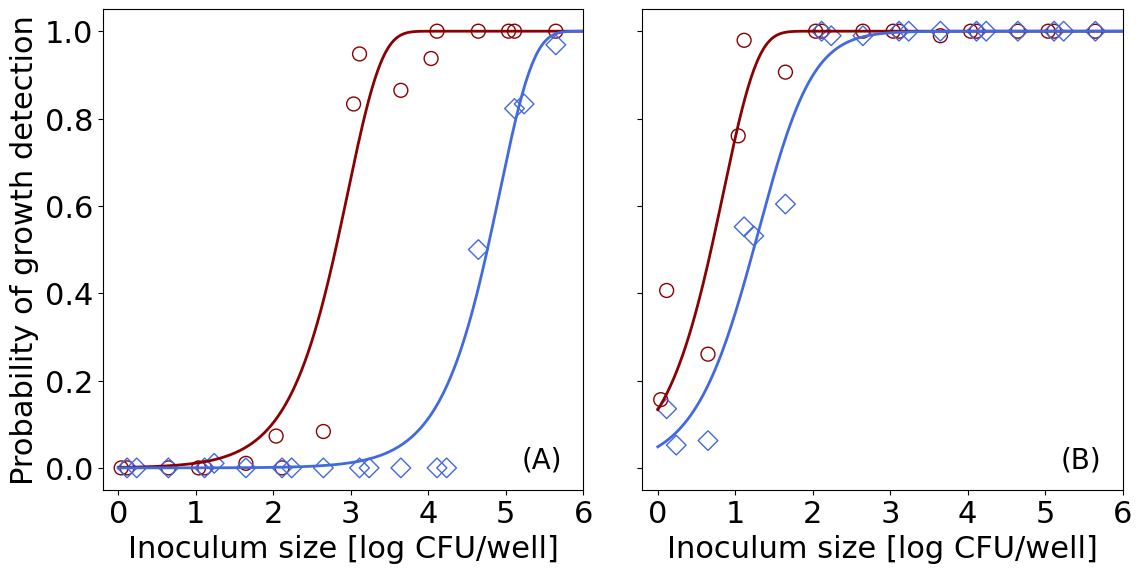

,Bacterial_species,Additive_type,Stress_level,Additive_concentration,Elapsed_time_[days],model_type,RMSE,AIC,parameter_1,parameter_2,parameter_set
0,B.cereus,Glycine_[w/v_%],Low,1.4,3,beta_poisson,0.059229,-46.666569,1.731386,1.841910e+02,"[alpha,beta]"
1,B.cereus,Glycine_[w/v_%],High,1.6,3,beta_poisson,0.050372,-52.498066,15.888383,2.692858e+05,"[alpha,beta]"
2,B.cereus,Glycine_[w/v_%],Low,1.4,7,beta_poisson,0.050436,-52.451771,1.760015,1.901156e+01,"[alpha,beta]"
3,B.cereus,Glycine_[w/v_%],High,1.6,7,beta_poisson,0.028586,-72.891881,11.191175,1.098279e+05,"[alpha,beta]"
4,B.cereus,NaCl_[w/v_%],Low,7.0,3,beta_poisson,0.116495,-22.314817,1.745485,4.423206e+02,"[alpha,beta]"
5,B.cereus,NaCl_[w/v_%],High,7.5,3,beta_poisson,0.101425,-27.301949,15.051863,1.517055e+05,"[alpha,beta]"
6,B.cereus,NaCl_[w/v_%],Low,7.0,7,beta_poisson,0.045979,-55.782610,2.522146,5.980634e-01,"[alpha,beta]"
7,B.cereus,NaCl_[w/v_%],High,7.5,7,beta_poisson,0.059070,-46.763191,0.844231,1.652936e+00,"[alpha,beta]"
8,E.coli,Glycine_[w/v_%],Low,1.7,3,beta_poisson,0.042627,-58.507600,4.636197,1.450938e+05,"[alpha,beta]"
9,E.coli,Glycine_[w/v_%],High,1.8,3,beta_poisson,0.023767,-79.539096,896.408088,1.031470e+08,"[alpha,beta]"


In [ ]:
### Beta-Poisson model by least squared method for E. coli data

plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 22

df_all = df.copy()
# preprocessing -filtering
## E.coli, Day3
df_Ec_day3 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 3)
    ].copy()
# lower stress condition
df_Ec_lower_day3 = df_Ec_day3[
    (df_Ec_day3["NaCl_[w/v_%]"] == 6.5) #18
].copy()
# higher stress condition
df_Ec_higher_day3 = df_Ec_day3[
    (df_Ec_day3["NaCl_[w/v_%]"] == 7.0) #18
].copy()

## E.coli, Day7
df_Ec_day7 = df_all[
    (df_all["Bacteria"] == "E.coli") &
    (df_all["Elapsed_time_[days]"] == 7)
    ].copy()
# lower stress condition
df_Ec_lower_day7 = df_Ec_day7[
    (df_Ec_day7["NaCl_[w/v_%]"] == 6.5) #18
].copy()
# higher stress condition
df_Ec_higher_day7 = df_Ec_day7[
    (df_Ec_day7["NaCl_[w/v_%]"] == 7.0) #18
].copy()

# defining Probability of growth detection "P(n)" & removing if there are missing value
## Day3, lower condition
df_Ec_lower_day3["Growth_probability"] = df_Ec_lower_day3["Number_of_growth_well"] / 96
df_Ec_lower_day3["Inoculum_size"] = df_Ec_lower_day3["Inoculum_size_[CFU/well]"]
df_Ec_lower_day3 = df_Ec_lower_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day3, higher condition
df_Ec_higher_day3["Growth_probability"] = df_Ec_higher_day3["Number_of_growth_well"] / 96
df_Ec_higher_day3["Inoculum_size"] = df_Ec_higher_day3["Inoculum_size_[CFU/well]"]
df_Ec_higher_day3 = df_Ec_higher_day3.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, lower condition
df_Ec_lower_day7["Growth_probability"] = df_Ec_lower_day7["Number_of_growth_well"] / 96
df_Ec_lower_day7["Inoculum_size"] = df_Ec_lower_day7["Inoculum_size_[CFU/well]"]
df_Ec_lower_day7 = df_Ec_lower_day7.dropna(subset=["Inoculum_size", "Growth_probability"])
## Day7, higher condition
df_Ec_higher_day7["Growth_probability"] = df_Ec_higher_day7["Number_of_growth_well"] / 96
df_Ec_higher_day7["Inoculum_size"] = df_Ec_higher_day7["Inoculum_size_[CFU/well]"]
df_Ec_higher_day7 = df_Ec_higher_day7.dropna(subset=["Inoculum_size", "Growth_probability"])



# ===== fitting for Day3 =====
## lower Day3
n_lower_3 = df_Ec_lower_day3["Inoculum_size"].values
y_lower_3 = df_Ec_lower_day3["Growth_probability"].values
res_lower_3 = minimize(loss, x0=x0,
                    args=(n_lower_3, y_lower_3),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_lower_3, beta_hat_lower_3 = res_lower_3.x
print(f"推定されたalpha,beta(lower, Day3): {alpha_hat_lower_3:.5f}, {beta_hat_lower_3:.5f}")
# lower additive stress のRMSE
pred_lower_3 = beta_poisson_model(n_lower_3, alpha_hat_lower_3, beta_hat_lower_3)
rmse_lower_3 = np.sqrt(np.mean((pred_lower_3 - y_lower_3) ** 2))
print(f"RMSE (lower, Day3): {rmse_lower_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_lower_day3,
    stress_level="Low",
    additive_col="NaCl_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_lower_3,
    y_pred=pred_lower_3,
    params=[alpha_hat_lower_3, beta_hat_lower_3],
    parameter_names=["alpha", "beta"],
)

n_higher_3 = df_Ec_higher_day3["Inoculum_size"].values
y_higher_3 = df_Ec_higher_day3["Growth_probability"].values
res_higher_3 = minimize(loss, x0=x0,
                    args=(n_higher_3, y_higher_3),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_higher_3, beta_hat_higher_3 = res_higher_3.x
print(f"推定されたalpha,beta(higher, Day3): {alpha_hat_higher_3:.5f}, {beta_hat_higher_3:.5f}")
# higher additive stress のRMSE
pred_higher_3 = beta_poisson_model(n_higher_3, alpha_hat_higher_3, beta_hat_higher_3)
rmse_higher_3 = np.sqrt(np.mean((pred_higher_3 - y_higher_3) ** 2))
print(f"RMSE (higher, Day3): {rmse_higher_3:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_higher_day3,
    stress_level="High",
    additive_col="NaCl_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_higher_3,
    y_pred=pred_higher_3,
    params=[alpha_hat_higher_3, beta_hat_higher_3],
    parameter_names=["alpha", "beta"],
)

n_plot_lower_3 = np.logspace(0, 6, 300)
y_plot_lower_3 = beta_poisson_model(n_plot_lower_3, alpha_hat_lower_3, beta_hat_lower_3)

n_plot_higher_3 = np.logspace(0, 6, 300)
y_plot_higher_3 = beta_poisson_model(n_plot_higher_3, alpha_hat_higher_3, beta_hat_higher_3)

# ===== fitting for Day7 =====
n_lower_7 = df_Ec_lower_day7["Inoculum_size"].values
y_lower_7 = df_Ec_lower_day7["Growth_probability"].values
res_lower_7 = minimize(loss, x0=x0,
                    args=(n_lower_7, y_lower_7),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_lower_7, beta_hat_lower_7 = res_lower_7.x
print(f"推定されたalpha,beta(lower, day7): {alpha_hat_lower_7:.5f}, {beta_hat_lower_7:.5f}")
# lower additive stress のRMSE
pred_lower_7 = beta_poisson_model(n_lower_7, alpha_hat_lower_7, beta_hat_lower_7)
rmse_lower_7 = np.sqrt(np.mean((pred_lower_7 - y_lower_7) ** 2))
print(f"RMSE (lower, Day7): {rmse_lower_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_lower_day7,
    stress_level="Low",
    additive_col="NaCl_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_lower_7,
    y_pred=pred_lower_7,
    params=[alpha_hat_lower_7, beta_hat_lower_7],
    parameter_names=["alpha", "beta"],
)

n_higher_7 = df_Ec_higher_day7["Inoculum_size"].values
y_higher_7 = df_Ec_higher_day7["Growth_probability"].values
res_higher_7 = minimize(loss, x0=x0,
                    args=(n_higher_7, y_higher_7),
                    method="L-BFGS-B",
                    bounds=bounds)
alpha_hat_higher_7, beta_hat_higher_7 = res_higher_7.x
print(f"推定されたalpha,beta(higher, Day7): {alpha_hat_higher_7:.5f}, {beta_hat_higher_7:.5f}")
# higher additive stress のRMSE
pred_higher_7 = beta_poisson_model(n_higher_7, alpha_hat_higher_7, beta_hat_higher_7)
rmse_higher_7 = np.sqrt(np.mean((pred_higher_7 - y_higher_7) ** 2))
print(f"RMSE (higher, Day7): {rmse_higher_7:.5f}")
df_results = add_fit_result_from_slice(
    df_results,
    df_slice=df_Ec_higher_day7,
    stress_level="High",
    additive_col="NaCl_[w/v_%]",
    model_type="beta_poisson",
    y_obs=y_higher_7,
    y_pred=pred_higher_7,
    params=[alpha_hat_higher_7, beta_hat_higher_7],
    parameter_names=["alpha", "beta"],
)

n_plot_lower_7 = np.logspace(0, 6, 300)
y_plot_lower_7 = beta_poisson_model(n_plot_lower_7, alpha_hat_lower_7, beta_hat_lower_7)

n_plot_higher_7 = np.logspace(0, 6, 300)
y_plot_higher_7 = beta_poisson_model(n_plot_higher_7, alpha_hat_higher_7, beta_hat_higher_7)

#### Figure print
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---- (A) Day3 ----
ax = axes[0]
ax.scatter(np.log10(n_lower_3), y_lower_3,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_3), y_lower_3, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_3), y_plot_lower_3,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_3), y_higher_3,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_3), y_higher_3, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_3), y_plot_higher_3,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(A)', fontsize=20)
ax.set_box_aspect(1)

# ---- (B) Day7 ----
ax = axes[1]
ax.scatter(np.log10(n_lower_7), y_lower_7,
           marker="o", color='darkred',
           facecolors='None', edgecolors='darkred',
           s=100, label="")
# ax.scatter(np.log10(n_lower_7), y_lower_7, marker="o", color='darkred', facecolors='None', edgecolors='darkred', s=100, label="NaCl 6.5%(w/v)")
ax.plot(np.log10(n_plot_lower_7), y_plot_lower_7,
        color='darkred', lw=2)

ax.scatter(np.log10(n_higher_7), y_higher_7,
           marker="D", color='royalblue',
           facecolors='None', edgecolors='royalblue',
           s=100, label="")
# ax.scatter(np.log10(n_higher_7), y_higher_7, marker="D", color='royalblue', facecolors='None', edgecolors='royalblue', s=100, label="NaCl 7.0%(w/v)")
ax.plot(np.log10(n_plot_higher_7), y_plot_higher_7,
        color='royalblue', lw=2)

ax.set_xlabel("Inoculum size [log CFU/well]")
# yラベルは左だけでもよければコメントアウトしてOK
# ax.set_ylabel("Probability of growth detection")
ax.set_xlim(-0.2, 6)
ax.set_ylim(-0.05, 1.05)
ax.set_xticks(np.arange(0, 6.1, 1))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.text(5.2, 0, '(B)', fontsize=20)
ax.set_box_aspect(1)

fig.patch.set_alpha(0)
plt.tight_layout()
plt.show()
display(df_results)

## Saving dataframe as CSV file
# df_results.to_csv(RESULTS_FILE, encoding="utf-8-sig", sep=",", na_rep="", index=False, mode="w")

## Saving Figures
### NaCl
#### TIFF
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Ecoli_NaCl_65_70_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Ecoli_NaCl_65_70_transparent_ver2026Jan26th.tiff", bbox_inches='tight', pad_inches=0.1, transparent=True)

#### PDF
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Ecoli_NaCl_65_70_ver2026Jan26th.pdf", bbox_inches='tight', pad_inches=0.1, transparent=False)
# fig.savefig("/workspace/results/figures/scatter_fit_BetaPoisson_least_square_Ecoli_NaCl_65_70_transparent_ver2026Jan26th.pdf", bbox_inches='tight', pad_inches=0.1, transparent=True)


In [28]:
display(df_results)

## Saving dataframe as CSV file
# df_results.to_csv(RESULTS_FILE, encoding="utf-8-sig", sep=",", na_rep="", index=False, mode="w")


,Bacterial_species,Additive_type,Stress_level,Additive_concentration,Elapsed_time_[days],model_type,RMSE,AIC,parameter_1,parameter_2,parameter_set
0,B.cereus,Glycine_[w/v_%],Low,1.4,3,exponential,0.065526,-45.029191,0.006151,NaN,[p]
1,B.cereus,Glycine_[w/v_%],High,1.6,3,exponential,0.049834,-54.884385,0.000056,NaN,[p]
2,B.cereus,Glycine_[w/v_%],Low,1.4,7,exponential,0.057032,-50.027200,0.060982,NaN,[p]
3,B.cereus,Glycine_[w/v_%],High,1.6,7,exponential,0.028204,-75.377332,0.000096,NaN,[p]
4,B.cereus,NaCl_[w/v_%],Low,7.0,3,exponential,0.118642,-23.657476,0.003054,NaN,[p]
5,B.cereus,NaCl_[w/v_%],High,7.5,3,exponential,0.099942,-29.832269,0.000096,NaN,[p]
6,B.cereus,NaCl_[w/v_%],Low,7.0,7,exponential,0.092383,-32.663280,1.000000,NaN,[p]
7,B.cereus,NaCl_[w/v_%],High,7.5,7,exponential,0.083110,-36.471520,0.313590,NaN,[p]
8,E.coli,Glycine_[w/v_%],Low,1.7,3,exponential,0.043677,-59.632058,0.000029,NaN,[p]
9,E.coli,Glycine_[w/v_%],High,1.8,3,exponential,0.026850,-77.147244,0.000010,NaN,[p]
